# Justificativas para limpeza de dados

Limpeza executada em src/data_cleaning.py.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import missingno as msno

import data_cleaning as dc

df = dc.df

## 1. Valores inválidos e parsing de colunas

As colunas númericas apresentam o caractere \N e números decimais com vírgula (strings). Valores inválidos causam erros no parsing de colunas. Os nulos são discutidos na sessão 3.

In [2]:
def not_is_num(num):
    try:
        float(num)
        return False
    except ValueError:
        return True

invalids = []
for col_name in dc.num_cols:
    counts_idx = df[col_name].value_counts().index
    not_is_num_list = list(map(not_is_num, counts_idx))
    invalids.append(list(counts_idx[not_is_num_list]))

pd.Series(invalids, index=dc.num_cols)

ano                                                                   []
vagas_ps                                                            [\N]
inscritos_ps                                                        [\N]
aprovados_ps                                                        [\N]
ingressantes_ps                                                     [\N]
vagas_sisu                                                          [\N]
ingressantes_sisu                                                   [\N]
ingressantes_provar                                                 [\N]
ingressantes_outros                                                 [\N]
matriculados           [0,00, \N, 21,00, 60,00, 121,50, 86,00, 4,00, ...
evadidos                                                            [\N]
concluintes                                                         [\N]
rel_cand_vaga          [0,00, \N, 1,00, 0,24, 0,33, 0,54, 0,48, 0,98,...
dtype: object

##### **Decisão**: Substituir \N por valor nulo, vírgula por ponto e fazer parsing adequado das colunas.

In [3]:
dc.fix_invalid_data()

## 2. Manipulação de colunas

Há as seguintes regras esperadas entre colunas numéricas:

\begin{align*}
    \text{vagas\_ps} &\geq \text{ingressantes\_ps} \\
    \text{aprovados\_ps} &\geq \text{ingressantes\_ps} \\
    \text{inscritos\_ps} &\geq \text{aprovados\_ps} \\
    \text{vagas\_sisu} &\geq \text{ingressantes\_sisu}
\end{align*}

Entretanto, existem exceções para cada regra. As exceções da primeira regra cobrem 27% dos dados, enquanto as exceções das demais cobrem 8-9%. Como ingressantes_ps participa de outra regra além da primeira, notamos que vagas_ps é responsável pela maior parte da alta ocorrência de exceções, sendo julgada, portanto, como coluna pouco confiável.

Obs. 1: As exceções também podem incluir valores nulos, não necessariamente comparação numérica.

Obs. 2: As regras são suposições do autor deste projeto, pois não há nada diretamente a favor ou contra na documentação original dos dados com relação à elas. Uma possível solução, no caso de ter o contato dos responsáveis pelos dados, seria questionar sobre as aparentes inconsistências, investigando a existência de regras ocultas.

In [4]:
def pct_rule(col1, col2):
    quant = len(df[df[col1] < df[col2]])
    print(f"{f'{col1} < {col2}:':<32}{quant/len(df):.2f}")

pct_rule('vagas_ps', 'ingressantes_ps')
pct_rule('aprovados_ps', 'ingressantes_ps')
pct_rule('inscritos_ps', 'aprovados_ps')
pct_rule('vagas_sisu', 'ingressantes_sisu')

vagas_ps < ingressantes_ps:     0.27
aprovados_ps < ingressantes_ps: 0.08
inscritos_ps < aprovados_ps:    0.08
vagas_sisu < ingressantes_sisu: 0.09


##### **Decisão**: Deletar as colunas vagas_ps e rel_cand_vaga (depende de vagas_ps).

In [5]:
dc.manipulates_cols()

## 3. Valores nulos

No ano 2026 originalmente não havia concluintes, então ela foi criada e preenchida com valor nulo para ser feita a concatenação dos CSVs, portanto desconsideramos esses nulos. Dessa forma, contabilizamos 13 linhas com nulos, 0,85% dos dados. Não existem outros valores nulos na coluna concluintes em outros anos além daqueles já contemplados pelas 13 linhas.

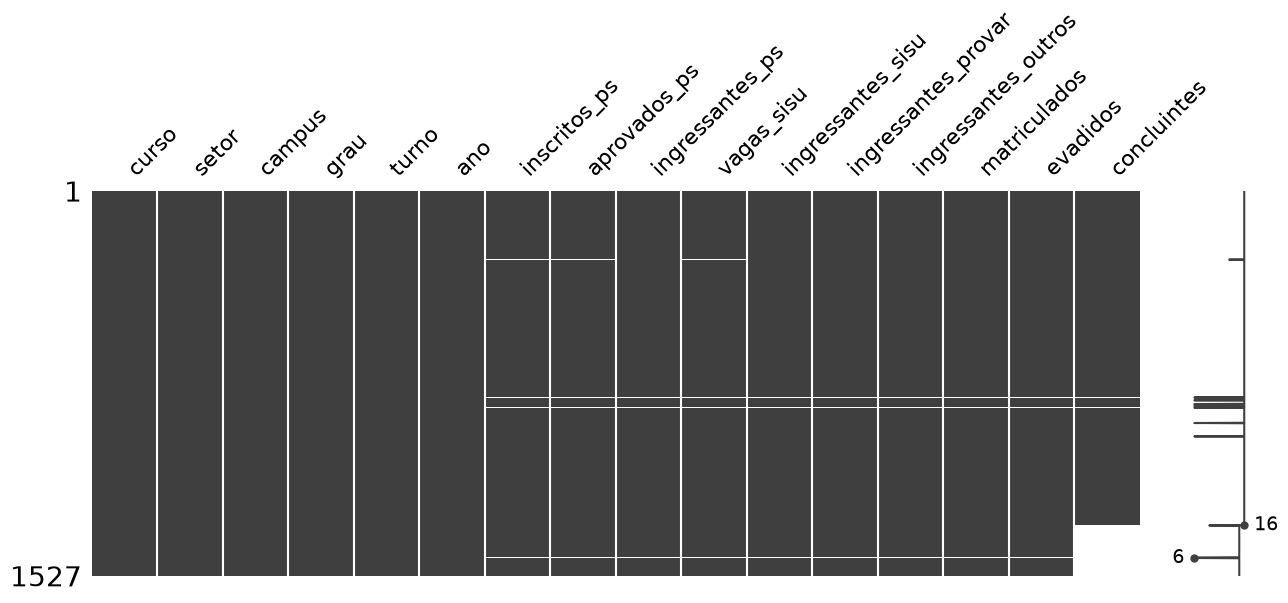

13 linhas com nulos, 0.0085 dos dados
Nulos de concluintes em outros anos não já contabilizados: 0


In [6]:
# Desconsidera concluintes
cols = df.columns.difference(['concluintes'])

msno.matrix(df, figsize=(15, 5))
plt.show()

idxs = df.index[df[cols].isna().any(axis=1).values]
idxs_len = len(idxs)
print(f'{idxs_len} linhas com nulos, {idxs_len/len(df):.2} dos dados')

df_aux = df.drop(index=idxs)
n_na = df_aux.loc[df_aux['ano'] != 2026, 'concluintes'].isna().sum()
print('Nulos de concluintes em outros anos não já contabilizados:', n_na)


##### **Decisão**: Deletar todas as linhas com valores nulos desconsiderando coluna concluintes.

In [7]:
dc.drop_na()